# Common post-processing — Original Milan vs Final Composed Brunelli

This notebook contains **no model simulation equations**.

It reads outputs generated independently by notebooks 01 and 02 and applies one common Brunelli observation mapping and one common implementation of the evaluation metrics. The final composed outputs correspond to the retained Brunelli configuration with the SLA-based crop-damage interface.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr,spearmanr

HERE=Path.cwd().resolve()
DATASET=HERE/"brunelli_final_dataset.csv"
MILAN_DIR=HERE/"milan_outputs"
COMPOSED_DIR=HERE/"composed_outputs"
OUT=HERE/"comparison_outputs"
OUT.mkdir(exist_ok=True)

for p in [DATASET,MILAN_DIR,COMPOSED_DIR]:
    assert p.exists(),p

NORMALIZATION=False
AMPLITUDE_SCALING=False
SMOOTHING=False
POSTHOC_SHIFT=False
TRAP_Q=False


In [2]:
raw=pd.read_csv(DATASET,parse_dates=["datetime"]).sort_values("datetime").reset_index(drop=True)
start=raw["datetime"].min()
raw["Day_float"]=(raw["datetime"]-start).dt.total_seconds()/86400.0
raw["Day"]=np.floor(raw["Day_float"]).astype(int)

EGG_LARVA_DAYS=np.array([0,6,13,20,27,34,41,48,55,62,69],dtype=int)
ADULT_DAYS=np.array([0,7,14,21,28,36,42,48,55,62,69],dtype=int)

daily_first=raw.groupby("Day",as_index=False).agg(
    Eggs=("Eggs","first"),Larvae=("Larvae","first"),Adults=("Adults_Brunelli","first"))
egg_obs=daily_first.set_index("Day").loc[EGG_LARVA_DAYS,"Eggs"].to_numpy(float)
larva_obs=daily_first.set_index("Day").loc[EGG_LARVA_DAYS,"Larvae"].to_numpy(float)
adult_obs=daily_first.set_index("Day").loc[ADULT_DAYS,"Adults"].to_numpy(float)

milan_el=pd.read_csv(MILAN_DIR/"milan_egg_larva_survey_predictions.csv")
milan_a=pd.read_csv(MILAN_DIR/"milan_adult_interval_predictions.csv")
comp_el=pd.read_csv(COMPOSED_DIR/"composed_egg_larva_survey_predictions.csv")
comp_a=pd.read_csv(COMPOSED_DIR/"composed_adult_interval_predictions.csv")

assert np.array_equal(milan_el["Day"].to_numpy(int),EGG_LARVA_DAYS)
assert np.array_equal(comp_el["Day"].to_numpy(int),EGG_LARVA_DAYS)
assert np.array_equal(milan_a["Interval_end_day"].to_numpy(int),ADULT_DAYS[1:])
assert np.array_equal(comp_a["Interval_end_day"].to_numpy(int),ADULT_DAYS[1:])

milan_egg=milan_el["Milan_Egg"].to_numpy(float)
milan_larva=milan_el["Milan_Larva"].to_numpy(float)
milan_adult=milan_a["Milan_Adult_interval_exposure"].to_numpy(float)

composed_egg=comp_el["Composed_Egg"].to_numpy(float)
composed_larva=comp_el["Composed_Larva"].to_numpy(float)
composed_adult=comp_a["Composed_Adult_interval_exposure"].to_numpy(float)


In [3]:
def direction_count(obs,pred):
    obs=np.asarray(obs,float); pred=np.asarray(pred,float)
    return int(np.sum(np.sign(np.diff(obs))==np.sign(np.diff(pred))))

def metric_block(obs,pred,support_days):
    obs=np.asarray(obs,float); pred=np.asarray(pred,float); support_days=np.asarray(support_days,int)
    return {
        "Pearson_r":float(pearsonr(obs,pred)[0]),
        "Spearman_rho":float(spearmanr(obs,pred)[0]),
        "Direction_match":direction_count(obs,pred),
        "Direction_total":len(obs)-1,
        "Sim_peak_day_or_interval_end":int(support_days[np.argmax(pred)]),
        "Observed_peak_day_or_interval_end":int(support_days[np.argmax(obs)]),
        "Peak_timing_error_days":int(support_days[np.argmax(pred)]-support_days[np.argmax(obs)]),
    }

def stage_table(name,egg,larva,adult):
    return pd.DataFrame([
        {"Model":name,"Stage":"Egg",**metric_block(egg_obs,egg,EGG_LARVA_DAYS)},
        {"Model":name,"Stage":"Larva",**metric_block(larva_obs,larva,EGG_LARVA_DAYS)},
        {"Model":name,"Stage":"Adult interval",**metric_block(adult_obs[1:],adult,ADULT_DAYS[1:])},
    ])

metrics=pd.concat([
    stage_table("Original Milan",milan_egg,milan_larva,milan_adult),
    stage_table("Final composed",composed_egg,composed_larva,composed_adult),
],ignore_index=True)
display(metrics)
metrics.to_csv(OUT/"Milan_vs_Composed_metrics_SEPARATE_MODELS.csv",index=False)


,Model,Stage,Pearson_r,Spearman_rho,Direction_match,Direction_total,Sim_peak_day_or_interval_end,Observed_peak_day_or_interval_end,Peak_timing_error_days
0,Original Milan,Egg,0.568687,0.665150,5,10,69,41,28
1,Original Milan,Larva,0.478292,0.409091,5,10,69,41,28
2,Original Milan,Adult interval,-0.241689,-0.212121,5,9,69,36,33
3,Final composed,Egg,0.783831,0.874718,8,10,41,41,0
4,Final composed,Larva,0.777931,0.727273,8,10,41,41,0
5,Final composed,Adult interval,0.738643,0.636364,7,9,36,36,0


In [4]:
M=metrics[metrics["Model"]=="Original Milan"].set_index("Stage")
C=metrics[metrics["Model"]=="Final composed"].set_index("Stage")

def dmatch(row):
    return f"{int(row['Direction_match'])}/{int(row['Direction_total'])}"

def perr(row):
    v=int(row['Peak_timing_error_days'])
    return "0 d" if v==0 else f"{v:+d} d"

change_table=pd.DataFrame([
    ["Egg Pearson r",f"{M.loc['Egg','Pearson_r']:.3f}",f"{C.loc['Egg','Pearson_r']:.3f}",
     f"{M.loc['Egg','Pearson_r']:.3f} → {C.loc['Egg','Pearson_r']:.3f}"],
    ["Larva Pearson r",f"{M.loc['Larva','Pearson_r']:.3f}",f"{C.loc['Larva','Pearson_r']:.3f}",
     f"{M.loc['Larva','Pearson_r']:.3f} → {C.loc['Larva','Pearson_r']:.3f}"],
    ["Adult Pearson r",f"{M.loc['Adult interval','Pearson_r']:.3f}",f"{C.loc['Adult interval','Pearson_r']:.3f}",
     f"{M.loc['Adult interval','Pearson_r']:.3f} → {C.loc['Adult interval','Pearson_r']:.3f}"],
    ["Egg direction match",dmatch(M.loc['Egg']),dmatch(C.loc['Egg']),f"{dmatch(M.loc['Egg'])} → {dmatch(C.loc['Egg'])}"],
    ["Larva direction match",dmatch(M.loc['Larva']),dmatch(C.loc['Larva']),f"{dmatch(M.loc['Larva'])} → {dmatch(C.loc['Larva'])}"],
    ["Adult direction match",dmatch(M.loc['Adult interval']),dmatch(C.loc['Adult interval']),f"{dmatch(M.loc['Adult interval'])} → {dmatch(C.loc['Adult interval'])}"],
    ["Egg peak error",perr(M.loc['Egg']),perr(C.loc['Egg']),f"{perr(M.loc['Egg'])} → {perr(C.loc['Egg'])}"],
    ["Larva peak error",perr(M.loc['Larva']),perr(C.loc['Larva']),f"{perr(M.loc['Larva'])} → {perr(C.loc['Larva'])}"],
    ["Adult peak error",perr(M.loc['Adult interval']),perr(C.loc['Adult interval']),f"{perr(M.loc['Adult interval'])} → {perr(C.loc['Adult interval'])}"],
],columns=["Metric","Original Milan","Final composed","Change"])
display(change_table)
change_table.to_csv(OUT/"Thesis_change_table_SEPARATE_MODELS.csv",index=False)


,Metric,Original Milan,Final composed,Change
0,Egg Pearson r,0.569,0.784,0.569 → 0.784
1,Larva Pearson r,0.478,0.778,0.478 → 0.778
2,Adult Pearson r,-0.242,0.739,-0.242 → 0.739
3,Egg direction match,5/10,8/10,5/10 → 8/10
4,Larva direction match,5/10,8/10,5/10 → 8/10
5,Adult direction match,5/9,7/9,5/9 → 7/9
6,Egg peak error,+28 d,0 d,+28 d → 0 d
7,Larva peak error,+28 d,0 d,+28 d → 0 d
8,Adult peak error,+33 d,0 d,+33 d → 0 d


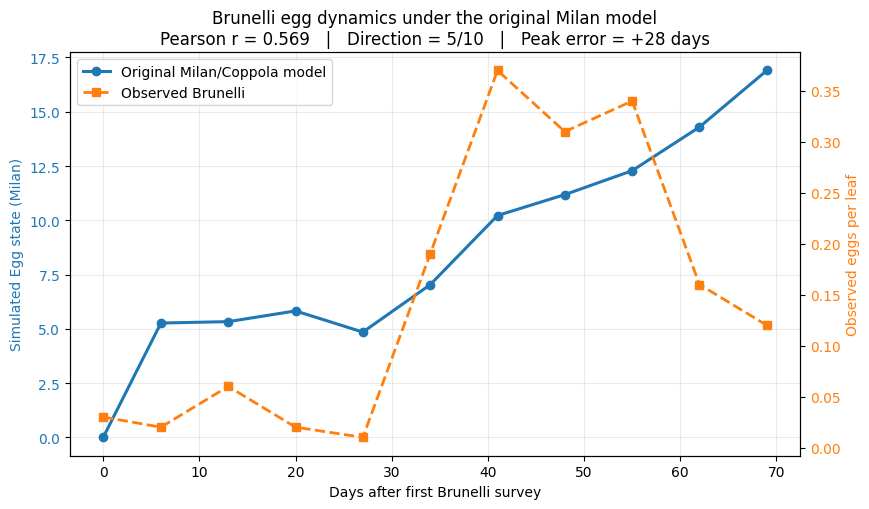

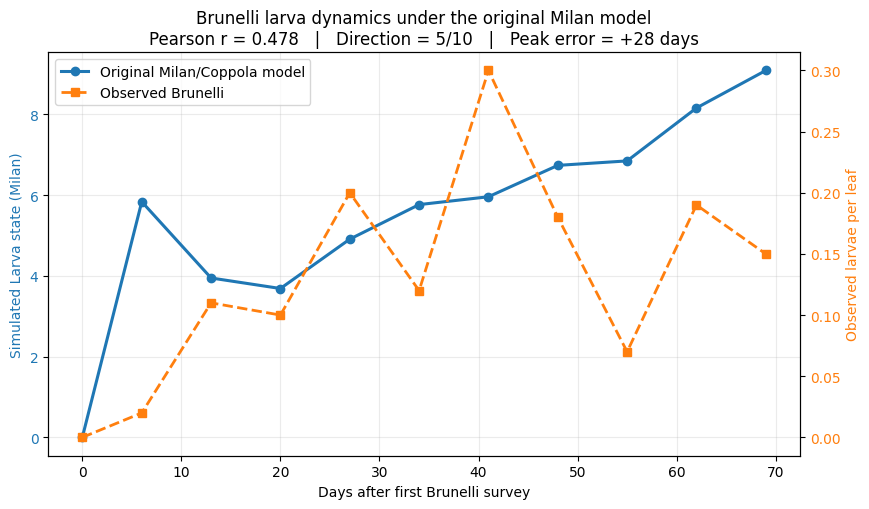

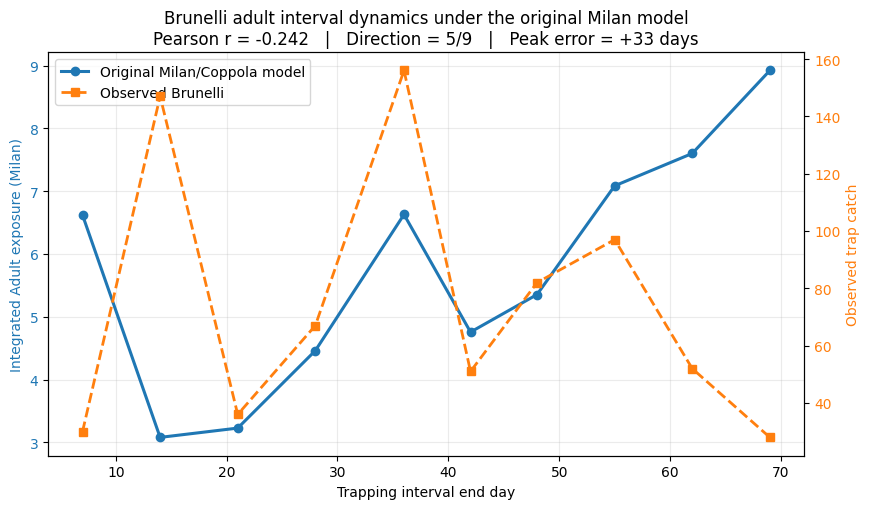

In [5]:
BLUE="#1f77b4"
ORANGE="#ff7f0e"

def mrow(stage):
    return metrics[(metrics["Model"]=="Original Milan")&(metrics["Stage"]==stage)].iloc[0]

def plot_milan(x,pred,obs,title,xlab,left_lab,right_lab,stage,filename):
    r=mrow(stage)
    fig,ax1=plt.subplots(figsize=(8.8,5.2))
    l1=ax1.plot(x,pred,marker="o",linewidth=2.2,color=BLUE,label="Original Milan/Coppola model")
    ax1.set_xlabel(xlab); ax1.set_ylabel(left_lab,color=BLUE)
    ax1.tick_params(axis="y",labelcolor=BLUE); ax1.grid(alpha=0.25)
    ax2=ax1.twinx()
    l2=ax2.plot(x,obs,marker="s",linestyle="--",linewidth=2.0,color=ORANGE,label="Observed Brunelli")
    ax2.set_ylabel(right_lab,color=ORANGE); ax2.tick_params(axis="y",labelcolor=ORANGE)
    lines=l1+l2
    ax1.legend(lines,[ln.get_label() for ln in lines],loc="best")
    ax1.set_title(title+"\n"+
        f"Pearson r = {r['Pearson_r']:.3f}   |   "+
        f"Direction = {int(r['Direction_match'])}/{int(r['Direction_total'])}   |   "+
        f"Peak error = {int(r['Peak_timing_error_days']):+d} days")
    fig.tight_layout()
    path=OUT/filename
    fig.savefig(path,dpi=220,bbox_inches="tight")
    plt.show()
    return path

egg_fig=plot_milan(EGG_LARVA_DAYS,milan_egg,egg_obs,
    "Brunelli egg dynamics under the original Milan model",
    "Days after first Brunelli survey","Simulated Egg state (Milan)","Observed eggs per leaf",
    "Egg","Figure_Milan_Egg_SEPARATE_two_colors.png")

larva_fig=plot_milan(EGG_LARVA_DAYS,milan_larva,larva_obs,
    "Brunelli larva dynamics under the original Milan model",
    "Days after first Brunelli survey","Simulated Larva state (Milan)","Observed larvae per leaf",
    "Larva","Figure_Milan_Larva_SEPARATE_two_colors.png")

adult_fig=plot_milan(ADULT_DAYS[1:],milan_adult,adult_obs[1:],
    "Brunelli adult interval dynamics under the original Milan model",
    "Trapping interval end day","Integrated Adult exposure (Milan)","Observed trap catch",
    "Adult interval","Figure_Milan_Adult_SEPARATE_two_colors.png")


In [6]:
expected_composed={
    "Egg":(0.7838305819274596,8,0),
    "Larva":(0.7779308840693925,8,0),
    "Adult interval":(0.7386430200035545,7,0),
}
for stage,(r_exp,d_exp,p_exp) in expected_composed.items():
    row=C.loc[stage]
    assert abs(row["Pearson_r"]-r_exp)<1e-12
    assert int(row["Direction_match"])==d_exp
    assert int(row["Peak_timing_error_days"])==p_exp

expected_milan={"Egg":(5,28),"Larva":(5,28),"Adult interval":(5,33)}
for stage,(d_exp,p_exp) in expected_milan.items():
    row=M.loc[stage]
    assert int(row["Direction_match"])==d_exp
    assert int(row["Peak_timing_error_days"])==p_exp

assert not any([NORMALIZATION,AMPLITUDE_SCALING,SMOOTHING,POSTHOC_SHIFT,TRAP_Q])
assert "Improvement" not in change_table.columns
assert change_table.columns[-1]=="Change"
assert change_table.loc[change_table["Metric"]=="Adult Pearson r","Change"].iloc[0]=="-0.242 → 0.739"

for p in [
    OUT/"Milan_vs_Composed_metrics_SEPARATE_MODELS.csv",
    OUT/"Thesis_change_table_SEPARATE_MODELS.csv",
    egg_fig,larva_fig,adult_fig,
]:
    assert Path(p).exists(),p

print("ALL UPDATED SEPARATE-MODEL COMPARISON CHECKS PASSED")


ALL UPDATED SEPARATE-MODEL COMPARISON CHECKS PASSED
